# Problem ID: Category09_Problem01 — Basic Queue-Based Traffic Signal Agent

### 1. Problem Scenario:
A smart traffic signal controls a two-road intersection. Vehicles arrive on the **North-South (NS)** road and the **East-West (EW)** road. At every signal cycle, the traffic-light agent observes the number of waiting vehicles on both roads and decides which direction should receive the next green signal.

The objective is to reduce traffic congestion by giving green to the direction with the larger queue.

### 2. System Specifications:
- **State Space ($S$):** The state is represented by the pair `(NS_queue, EW_queue)`, where each queue contains the current number of waiting vehicles.
- **Action Space ($A$):** 2 discrete actions: `0: NS GREEN`, `1: EW GREEN`.
- **Vehicle Service Rule:** During a green cycle, up to **2 vehicles** can pass from the selected direction.
- **Vehicle Arrival Rule:** After each signal cycle, a small number of new vehicles may arrive on both roads.
- **Reward Function:** The reward is the negative of the total number of vehicles remaining after the signal cycle:
  $$R = -(NS\_queue + EW\_queue)$$
- **Decision Rule:** The agent should normally select the direction having the larger queue. If both queues are equal, it should continue the previous green direction.

### 3. Student Implementation Deliverables:
1. **Task 1 (Cell 4):** Implement the queue-based `choose_action()` method. Select the direction with the larger queue and use the previous signal direction to break a tie.
2. **Task 2 (Cell 5):** Implement `update_agent()` to calculate the queue reduction after each signal cycle and maintain a simple running service estimate for the selected direction.
3. **Execute & Verify (Cells 6 & 7):** Run the simulation driver and inspect the reward trajectory and average queue-size trajectory.

In [1]:
# Cell 2: Standard Libraries & Environment Parameters (LOCKED)
import numpy as np
import matplotlib.pyplot as plt
import random

# Set deterministic seed for reproducible results
np.random.seed(42)
random.seed(42)

# Traffic Environment Parameters
MAX_QUEUE = 12
INITIAL_NS_QUEUE = 5
INITIAL_EW_QUEUE = 3
VEHICLES_SERVED_PER_GREEN = 2
MAX_STEPS_PER_EPISODE = 30

# Arrival range for each signal cycle
MIN_ARRIVAL = 0
MAX_ARRIVAL = 2

# Agent parameter for the running service estimate
ALPHA = 0.2

# Simulation Parameters
NUM_EPISODES = 100


In [2]:
# Cell 3: Environment Simulator Scaffold (LOCKED)
class EnvironmentEngine:
    def __init__(self):
        self.reset()

    def reset(self):
        """Reset both traffic queues and the signal phase."""
        self.ns_queue = INITIAL_NS_QUEUE
        self.ew_queue = INITIAL_EW_QUEUE
        self.current_phase = 0  # 0: NS GREEN, 1: EW GREEN
        return self._get_state()

    def _get_state(self):
        return (self.ns_queue, self.ew_queue)

    def step(self, action):
        """
        Executes one signal cycle.
        action: 0 -> NS GREEN, 1 -> EW GREEN
        Returns: (next_state, reward, done)
        """
        action = int(action)
        self.current_phase = action

        # Vehicles pass through the selected green direction
        if action == 0:
            self.ns_queue = max(0, self.ns_queue - VEHICLES_SERVED_PER_GREEN)
        else:
            self.ew_queue = max(0, self.ew_queue - VEHICLES_SERVED_PER_GREEN)

        # New vehicles arrive after the green cycle
        ns_arrivals = random.randint(MIN_ARRIVAL, MAX_ARRIVAL)
        ew_arrivals = random.randint(MIN_ARRIVAL, MAX_ARRIVAL)

        self.ns_queue = min(MAX_QUEUE, self.ns_queue + ns_arrivals)
        self.ew_queue = min(MAX_QUEUE, self.ew_queue + ew_arrivals)

        next_state = self._get_state()

        # Lower remaining queues produce a better reward
        reward = -(self.ns_queue + self.ew_queue)

        return next_state, float(reward), False


In [3]:
# Cell 4: [TASK 1] Agent Class & Queue-Based Action Selection (SOLUTION)
class TrafficLightAgent:
    def __init__(self, alpha=ALPHA):
        self.alpha = alpha
        self.current_phase = 0  # 0: NS GREEN, 1: EW GREEN
        self.service_estimate = np.zeros(2)

    def choose_action(self, state):
        ns_queue, ew_queue = state

        if ns_queue > ew_queue:
            action = 0
        elif ew_queue > ns_queue:
            action = 1
        else:
            action = self.current_phase

        self.current_phase = action
        return action


In [4]:
# Cell 5: [TASK 2] Agent Update / Running Service Estimate (SOLUTION)
def update_agent(self, state, action, reward, next_state, done):
    ns_queue, ew_queue = state
    next_ns_queue, next_ew_queue = next_state

    total_before = ns_queue + ew_queue
    total_after = next_ns_queue + next_ew_queue

    reduction = max(0, total_before - total_after)

    current_estimate = self.service_estimate[action]
    self.service_estimate[action] = (
        current_estimate
        + self.alpha * (reduction - current_estimate)
    )

# Attach the completed method to the agent class
TrafficLightAgent.update_agent = update_agent


In [5]:
# Cell 6: Simulation Execution & Test Driver (LOCKED)
env = EnvironmentEngine()
agent = TrafficLightAgent()

rewards_history = []
average_queue_history = []

for ep in range(NUM_EPISODES):
    state = env.reset()
    total_reward = 0.0
    queue_sum = 0.0

    for step in range(MAX_STEPS_PER_EPISODE):
        action = agent.choose_action(state)
        next_state, reward, done = env.step(action)
        agent.update_agent(state, action, reward, next_state, done)

        state = next_state
        total_reward += reward
        queue_sum += sum(state)

    rewards_history.append(total_reward)
    average_queue_history.append(queue_sum / MAX_STEPS_PER_EPISODE)

print(f"Simulation completed across {NUM_EPISODES} episodes.")
print(f"Average Reward (Last 20 Episodes): {np.mean(rewards_history[-20:]):.2f}")
print(f"Average Queue Size (Last 20 Episodes): {np.mean(average_queue_history[-20:]):.2f}")
print(f"Estimated NS Service: {agent.service_estimate[0]:.2f}")
print(f"Estimated EW Service: {agent.service_estimate[1]:.2f}")


Simulation completed across 100 episodes.
Average Reward (Last 20 Episodes): -292.60
Average Queue Size (Last 20 Episodes): 9.75
Estimated NS Service: 0.35
Estimated EW Service: 0.13


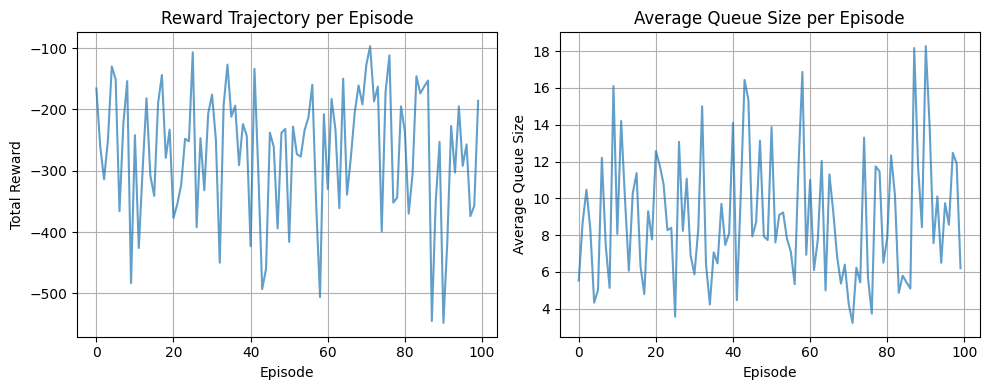

In [6]:
# Cell 7: Performance Metric Visualization (LOCKED)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(rewards_history, alpha=0.7)
plt.title("Reward Trajectory per Episode")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(average_queue_history, alpha=0.7)
plt.title("Average Queue Size per Episode")
plt.xlabel("Episode")
plt.ylabel("Average Queue Size")
plt.grid(True)

plt.tight_layout()
plt.show()
